<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockGPT2LoRA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# HANCOCK GPT-2 LoRA
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from peft import LoraConfig, get_peft_model, TaskType
!pip uninstall -y torchao

!pip install torchao

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))

## ============================================================
# 6. CONVERT EXACTLY SIX CLINICAL FEATURES INTO TEXT
# ============================================================

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def patient_to_text(row):

    # Feature 1: Age
    age = display_value(row["age_at_initial_diagnosis"])

    # Feature 2: Sex
    sex_value = str(row["sex"]).strip().lower()

    if sex_value in ["1", "male", "m"]:
        sex = "male"
    elif sex_value in ["0", "female", "f"]:
        sex = "female"
    else:
        sex = display_value(row["sex"])

    # Feature 3: Smoking status
    smoking_value = str(row["smoking_status"]).strip().lower()

    if smoking_value in ["0", "non-smoker", "nonsmoker", "never"]:
        smoking = "a non-smoker"
    elif smoking_value in ["1", "smoker", "current smoker", "yes"]:
        smoking = "a smoker"
    else:
        smoking = display_value(row["smoking_status"])

    # Feature 4: Primary tumour site
    site = display_value(row["primary_tumor_site"])

    # Feature 5: Primarily metastasis
    metastasis = display_value(row["primarily_metastasis"])

    # Feature 6: Pathological N stage
    n_stage = display_value(row["pN_stage"])

    prompt = (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available. "

        f"This patient is {age} years old and is {sex}. "
        f"The patient is {smoking}. "
        f"The primary tumour site is {site}. "
        f"The primarily metastasis status is {metastasis}. "
        f"Pathological nodal stage is {n_stage}. "

        "Based on these six clinical features, "
        "predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\nA:"
    )

    return prompt


# Verify exactly six input features
features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

assert len(features) == 6

print("Number of clinical features:", len(features))
print("Features:", features)

print("\nExample clinical prompt:")
print(patient_to_text(df.iloc[0]))



# Create text prompts for the original train/validation/test split

train_texts = [
    patient_to_text(row)
    for _, row in train_df.iterrows()
]

val_texts = [
    patient_to_text(row)
    for _, row in val_df.iterrows()
]

test_texts = [
    patient_to_text(row)
    for _, row in test_df.iterrows()
]

print("Training prompts:", len(train_texts))
print("Validation prompts:", len(val_texts))
print("Test prompts:", len(test_texts))



# ============================================================
# 7. LOAD TOKENIZER AND SELECT MAXIMUM LENGTH
# ============================================================
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Determine the length policy from training prompts only to avoid
# using validation/test data to choose preprocessing parameters.



TRAIN_PROMPT_LENGTHS = [
    len(tokenizer.encode(t, add_special_tokens=False))
    for t in train_texts
]
print("Training prompt tokens: min =", min(TRAIN_PROMPT_LENGTHS),
      "| median =", int(np.median(TRAIN_PROMPT_LENGTHS)),
      "| 95th percentile =", int(np.percentile(TRAIN_PROMPT_LENGTHS, 95)),
      "| max =", max(TRAIN_PROMPT_LENGTHS))
MAX_LENGTH = min(
    1024, max(32, int(np.ceil(max(TRAIN_PROMPT_LENGTHS) / 8) * 8))
)
if max(TRAIN_PROMPT_LENGTHS) > 1024:
    print("WARNING: Some training prompts exceed GPT-2's context limit.")
print("Selected MAX_LENGTH:", MAX_LENGTH)

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS,
      "| Learning rate:", LEARNING_RATE,
      "| Weight decay:", WEIGHT_DECAY)

# ============================================================
# 8. BUILD DATASETS AND DATA LOADERS
# ============================================================
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            encoded = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                encoded["input_ids"].squeeze(0),
                encoded["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        input_ids, attention_mask, label = self.items[index]
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "label": torch.tensor(label, dtype=torch.long)
        }

train_dataset = HPVTextDataset(train_texts, y_train)
val_dataset = HPVTextDataset(val_texts, y_val)
test_dataset = HPVTextDataset(test_texts, y_test)
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)


# ============================================================
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS WEIGHTS
#     UPDATED: LoRA integration only
# ============================================================

class HPVNetGPT2Text(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_classes=2,
                 dropout=DROPOUT):
        super().__init__()

        # Load the original GPT-2 backbone
        self.gpt2 = GPT2Model.from_pretrained(model_name)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        # NEW: Configure and apply LoRA to GPT-2 attention projections
        lora_config = LoraConfig(
            r=6,
            lora_alpha=12,
            target_modules=["c_attn"],
            lora_dropout=0.0,
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION
        )

        self.gpt2 = get_peft_model(self.gpt2, lora_config)

        # Keep the existing classification head unchanged
        hidden_size = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        # Keep the original last-token pooling unchanged
        hidden_states = outputs.last_hidden_state
        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]

        return self.classifier(pooled_output)


# Initialise the model
model = HPVNetGPT2Text().to(device)

# NEW: Display the number of trainable LoRA parameters
# in the GPT-2 backbone
model.gpt2.print_trainable_parameters()

# Keep the existing class-weight calculation unchanged
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print("Class weights [negative, positive]:",
      class_weights.detach().cpu().numpy())

print("Total trainable parameters (LoRA + classifier):",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


# Keep the existing weighted classification loss unchanged
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()


# UPDATED: Optimise only trainable parameters
# (LoRA adapters and the classification head)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 10. HPV SCORES, VALIDATION LOSS AND THRESHOLD SELECTION
# ============================================================
def get_hpv_scores(loader):
    model.eval()
    scores, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels_all.extend(batch["label"].numpy())
    return np.asarray(scores, dtype=float), np.asarray(labels_all, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total_loss, total_examples = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            loss = weighted_classification_loss(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n
    return total_loss / max(total_examples, 1)

def select_threshold(scores, labels):
    thresholds = np.unique(np.concatenate(([0.0], scores, [1.0])))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    # Maximise balanced accuracy; ties go to the threshold closest to 0.5.
    return max(results, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# ============================================================
# 11. TRAIN AND SAVE BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR = Path("ROC_HANCOCK_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":
        OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": {
        "value": float("inf"), "epoch": None, "threshold": None
    },
    "Validation_ROC_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_PR_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_Balanced_Accuracy": {
        "value": -float("inf"), "epoch": None, "threshold": None
    }
}
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum, train_examples = 0.0, 0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = weighted_classification_loss(logits, labels)
        loss.backward()
        optimizer.step()
        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_examples += n

    train_loss = train_loss_sum / max(train_examples, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_hpv_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    val_threshold, val_ba = select_threshold(val_scores, val_labels)
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss,
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba
    }
    for metric, value in metrics.items():
        improved = (
            value < best[metric]["value"] if metric == "Validation_Loss"
            else value > best[metric]["value"]
        )
        if improved:
            best[metric] = {
                "value": float(value), "epoch": epoch,
                "threshold": float(val_threshold)
            }
            torch.save(model.state_dict(), checkpoint_paths[metric])

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric, "Best_Epoch": info["epoch"],
        "Best_Validation_Metric": info["value"],
        "Threshold_Selected_On_Validation": info["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, info in best.items()
])
best_summary.to_csv(
    OUT_DIR / "best_validation_checkpoints.csv", index=False
)
print("\nBEST VALIDATION CHECKPOINTS\n", best_summary.to_string(index=False))

# ============================================================
# 12. EVALUATE CHECKPOINTS ON THE HELD-OUT TEST SET
# ============================================================
test_results, test_predictions = [], {}
for metric, path in checkpoint_paths.items():
    print(f"\n===== CHECKPOINT: {metric} =====")
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_hpv_scores(test_loader)
    threshold = best[metric]["threshold"]
    predictions = (scores >= threshold).astype(int)
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, zero_division=0)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    print("Best epoch:", best[metric]["epoch"])
    print(f"Validation threshold: {threshold:.6f}")
    print(classification_report(
        labels, predictions, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(
        f"Test ROC-AUC: {auc:.4f} | Test PR-AUC (AP): {ap:.4f} | "
        f"Test Balanced Accuracy: {ba:.4f} | F1: {f1:.4f}"
    )
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    test_results.append({
        "Dataset": "HANCOCK", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": auc, "Test_PR_AUC_Average_Precision": ap,
        "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })
    test_predictions[metric] = {
        "scores": scores, "predictions": predictions,
        "labels": labels, "threshold": threshold
    }
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": predictions, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{metric.lower()}.csv", index=False)

results_df = pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)
print("\nTEST RESULTS BY CHECKPOINT\n", results_df.to_string(index=False))

# ============================================================
# 13. SAVE ROC AND PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================
for metric, result in test_predictions.items():
    labels, scores = result["labels"], result["scores"]
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    safe_name = metric.lower()
    pd.DataFrame({
        "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
    }).to_csv(OUT_DIR / f"roc_coordinates_{safe_name}.csv", index=False)
    pd.DataFrame({
        "Precision": precision, "Recall": recall
    }).to_csv(
        OUT_DIR / f"precision_recall_coordinates_{safe_name}.csv",
        index=False
    )
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"HANCOCK GPT-2 Classifier ROC: {metric}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"roc_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(recall, precision, linewidth=2, label=f"PR-AUC (AP) = {ap:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"HANCOCK GPT-2 Classifier Precision-Recall: {metric}")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"precision_recall_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

# ============================================================
# 14. SAVE SETTINGS AND APPEND RESULTS TO COMPARISON CSV
# ============================================================
settings = {
    "Dataset": "HANCOCK", "Model": MODEL_NAME,
    "Model_Type": "GPT-2 Classifier",
    "Features": ", ".join(features), "Number_of_Features": len(features),
    "Target": target_col, "Positive_Class": 1,
    "Positive_Class_Name": "HPV Positive",
    "Learning_Rate": LEARNING_RATE, "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW", "Epochs": EPOCHS, "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Max_Length_Method": (
        "Training prompts only; rounded to multiple of 8; capped at 1024"
    ),
    "Random_Seed": SEED, "Train_Validation_Test_Split": "65/15/20 stratified",
    "SMOTE": False, "Gradient_Clipping": False,
    "Model_Type": "GPT-2 Classifier with LoRA",
    "GPT2_Backbone_Frozen": True, "Dropout": DROPOUT,
    "Class_Weights": str(class_weights.detach().cpu().numpy().tolist()),
    "Checkpoint_Selection": (
        "Best validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "Threshold_Selection": (
        "Maximise validation balanced accuracy; ties closest to 0.5"
    ),
    "HPV_Positive_Score": "Softmax probability for class 1 (HPV positive)",
    "Curves": (
        "Test ROC and precision-recall curves saved for each checkpoint"
    )
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison_rows = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC_Average_Precision",
    "Test_Balanced_Accuracy", "Test_F1"
]].rename(columns={"Test_PR_AUC_Average_Precision": "Test_PR_AUC"})

if comparison_file.exists():
    existing = pd.read_csv(comparison_file)
    for col in comparison_rows.columns:
        if col not in existing.columns:
            existing[col] = np.nan
    for col in existing.columns:
        if col not in comparison_rows.columns:
            comparison_rows[col] = np.nan
    combined = pd.concat(
        [existing, comparison_rows[existing.columns]], ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison_rows

combined.to_csv(comparison_file, index=False)
print("\nSaved classifier outputs to:", OUT_DIR.resolve())
print("AUC comparison file:", comparison_file.resolve())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 118.1 MB/s  0:00:00
Device: cuda
Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Number of clinical features: 6
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

Example clinical prompt:
Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. This patient is 60 years old and is male. The patient is a non-smoker. The primary tumour site is Oropharynx. The primarily metastasis status is no. Pathological nodal stage is pN1. Based on these six clinical features, predict whether the 

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Class weights [negative, positive]: [0.87398374 1.1684783 ]
Total trainable parameters (LoRA + classifier): 321410
Epoch 50/500 | Train Loss=0.6175 | Val Loss=0.6833 | Val ROC-AUC=0.6511 | Val PR-AUC=0.5747 | Val BA=0.6355 | Threshold=0.478146
Epoch 100/500 | Train Loss=0.3034 | Val Loss=1.0977 | Val ROC-AUC=0.6790 | Val PR-AUC=0.6176 | Val BA=0.6806 | Threshold=0.241726
Epoch 150/500 | Train Loss=0.1774 | Val Loss=2.1632 | Val ROC-AUC=0.6675 | Val PR-AUC=0.5615 | Val BA=0.6806 | Threshold=0.020490
Epoch 200/500 | Train Loss=0.1213 | Val Loss=1.9450 | Val ROC-AUC=0.6741 | Val PR-AUC=0.5917 | Val BA=0.6806 | Threshold=0.035166
Epoch 250/500 | Train Loss=0.1098 | Val Loss=3.4166 | Val ROC-AUC=0.6691 | Val PR-AUC=0.5943 | Val BA=0.6847 | Threshold=0.095777
Epoch 300/500 | Train Loss=0.0791 | Val Loss=2.9371 | Val ROC-AUC=0.6609 | Val PR-AUC=0.5534 | Val BA=0.6593 | Threshold=0.000999
Epoch 350/500 | Train Loss=0.07

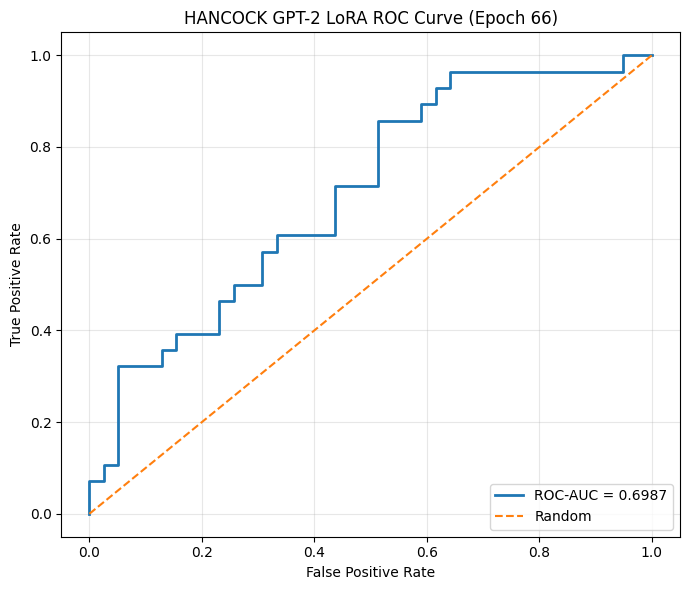

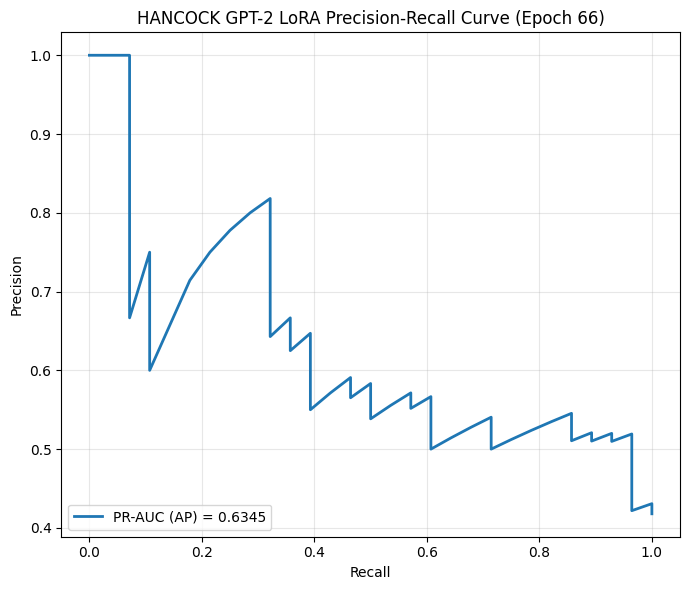

Checkpoint: Validation_PR_AUC
Best epoch: 66
Validation threshold: 0.508372
Test ROC-AUC: 0.6987
Test PR-AUC (AP): 0.6345
Test Balanced Accuracy: 0.6369
Test F1-score: 0.5862
Confusion matrix:
[[26 13]
 [11 17]]


In [4]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Load the epoch 66 checkpoint
checkpoint_path = checkpoint_paths["Validation_PR_AUC"]

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)
model.eval()

# Obtain test probabilities and labels
scores, labels = get_hpv_scores(test_loader)

# Use the threshold selected on validation data
threshold = best["Validation_PR_AUC"]["threshold"]

predictions = (scores >= threshold).astype(int)

# Calculate metrics
roc_auc = roc_auc_score(labels, scores)
pr_auc = average_precision_score(labels, scores)

# -------------------------
# ROC CURVE
# -------------------------
fpr, tpr, _ = roc_curve(labels, scores)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr, tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)
plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HANCOCK GPT-2 LoRA ROC Curve (Epoch 66)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "HANCOCK_GPT2_LoRA_Epoch66_ROC.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# -------------------------
# PRECISION-RECALL CURVE
# -------------------------
precision, recall, _ = precision_recall_curve(labels, scores)

plt.figure(figsize=(7, 6))
plt.plot(
    recall, precision,
    linewidth=2,
    label=f"PR-AUC (AP) = {pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HANCOCK GPT-2 LoRA Precision-Recall Curve (Epoch 66)")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "HANCOCK_GPT2_LoRA_Epoch66_PR.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# -------------------------
# PRINT RESULTS
# -------------------------
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

print("Checkpoint: Validation_PR_AUC")
print("Best epoch:", best["Validation_PR_AUC"]["epoch"])
print(f"Validation threshold: {threshold:.6f}")
print(f"Test ROC-AUC: {roc_auc:.4f}")
print(f"Test PR-AUC (AP): {pr_auc:.4f}")
print(f"Test Balanced Accuracy: {balanced_accuracy_score(labels, predictions):.4f}")
print(f"Test F1-score: {f1_score(labels, predictions):.4f}")
print("Confusion matrix:")
print(confusion_matrix(labels, predictions))

Device: cuda
Total patients: 332
Class distribution [negative, positive]: [191 141]

FOLD 1/3
Training patients: 187
Validation patients: 34
Held-out test patients: 111
Training classes: [107  80]
Validation classes: [20 14]
Test classes: [64 47]
Fold MAX_LENGTH: 104


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Total trainable parameters: 321410
Class weights [negative, positive]: [0.87383175 1.16875   ]
Fold 1 | Epoch 50/500 | Train Loss=0.6299 | Val Loss=0.6560 | Val ROC-AUC=0.7750 | Val PR-AUC=0.6037 | Val BA=0.8000 | Threshold=0.353884
Fold 1 | Epoch 100/500 | Train Loss=0.2246 | Val Loss=1.0508 | Val ROC-AUC=0.7214 | Val PR-AUC=0.6919 | Val BA=0.7214 | Threshold=0.864285
Fold 1 | Epoch 150/500 | Train Loss=0.1074 | Val Loss=1.4606 | Val ROC-AUC=0.7214 | Val PR-AUC=0.6724 | Val BA=0.7214 | Threshold=0.973963
Fold 1 | Epoch 200/500 | Train Loss=0.0997 | Val Loss=1.6286 | Val ROC-AUC=0.7250 | Val PR-AUC=0.6922 | Val BA=0.6964 | Threshold=0.522610
Fold 1 | Epoch 250/500 | Train Loss=0.0773 | Val Loss=2.0550 | Val ROC-AUC=0.7339 | Val PR-AUC=0.6483 | Val BA=0.7321 | Threshold=0.713742
Fold 1 | Epoch 300/500 | Train Loss=0.0770 | Val Loss=2.5384 | Val ROC-AUC=0.7214 | Val PR-AUC=0.6516 | Val BA=0.7214 | Threshold=0.9856

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Total trainable parameters: 321410
Class weights [negative, positive]: [0.87383175 1.16875   ]
Fold 2 | Epoch 50/500 | Train Loss=0.5500 | Val Loss=0.8342 | Val ROC-AUC=0.5464 | Val PR-AUC=0.4884 | Val BA=0.6321 | Threshold=0.367551
Fold 2 | Epoch 100/500 | Train Loss=0.2865 | Val Loss=2.3084 | Val ROC-AUC=0.4321 | Val PR-AUC=0.3879 | Val BA=0.5714 | Threshold=0.332832
Fold 2 | Epoch 150/500 | Train Loss=0.1486 | Val Loss=3.1354 | Val ROC-AUC=0.4143 | Val PR-AUC=0.3994 | Val BA=0.5321 | Threshold=0.960365
Fold 2 | Epoch 200/500 | Train Loss=0.0984 | Val Loss=3.1975 | Val ROC-AUC=0.4321 | Val PR-AUC=0.4742 | Val BA=0.5679 | Threshold=0.914167
Fold 2 | Epoch 250/500 | Train Loss=0.0519 | Val Loss=3.8971 | Val ROC-AUC=0.4857 | Val PR-AUC=0.5044 | Val BA=0.6036 | Threshold=0.773561
Fold 2 | Epoch 300/500 | Train Loss=0.0602 | Val Loss=3.7750 | Val ROC-AUC=0.4571 | Val PR-AUC=0.4532 | Val BA=0.5750 | Threshold=0.4955

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Total trainable parameters: 321410
Class weights [negative, positive]: [0.8703704 1.175    ]
Fold 3 | Epoch 50/500 | Train Loss=0.5786 | Val Loss=0.8100 | Val ROC-AUC=0.5679 | Val PR-AUC=0.5076 | Val BA=0.6750 | Threshold=0.559459
Fold 3 | Epoch 100/500 | Train Loss=0.1837 | Val Loss=1.8037 | Val ROC-AUC=0.6464 | Val PR-AUC=0.6747 | Val BA=0.7107 | Threshold=0.392018
Fold 3 | Epoch 150/500 | Train Loss=0.0892 | Val Loss=2.1986 | Val ROC-AUC=0.6893 | Val PR-AUC=0.6878 | Val BA=0.6857 | Threshold=0.108123
Fold 3 | Epoch 200/500 | Train Loss=0.1061 | Val Loss=3.2552 | Val ROC-AUC=0.6143 | Val PR-AUC=0.6508 | Val BA=0.6821 | Threshold=0.050622
Fold 3 | Epoch 250/500 | Train Loss=0.0851 | Val Loss=3.3866 | Val ROC-AUC=0.5679 | Val PR-AUC=0.6176 | Val BA=0.6536 | Threshold=0.999907
Fold 3 | Epoch 300/500 | Train Loss=0.0611 | Val Loss=3.8197 | Val ROC-AUC=0.5857 | Val PR-AUC=0.6288 | Val BA=0.6536 | Threshold=0.999453

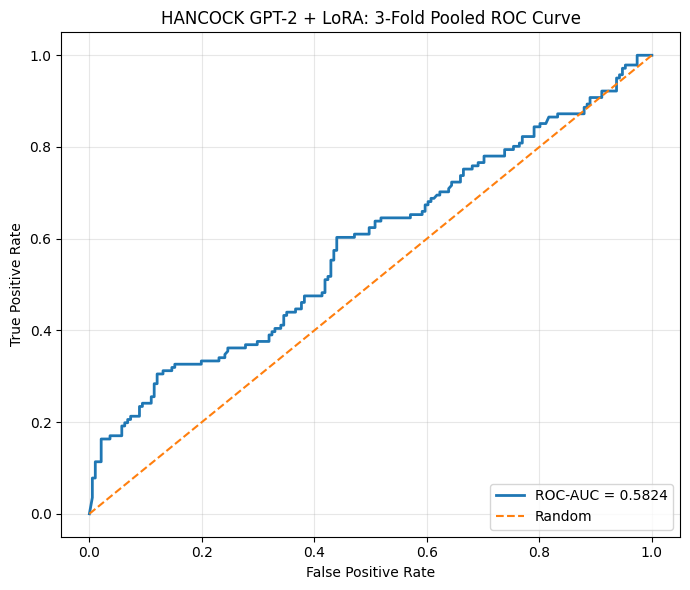

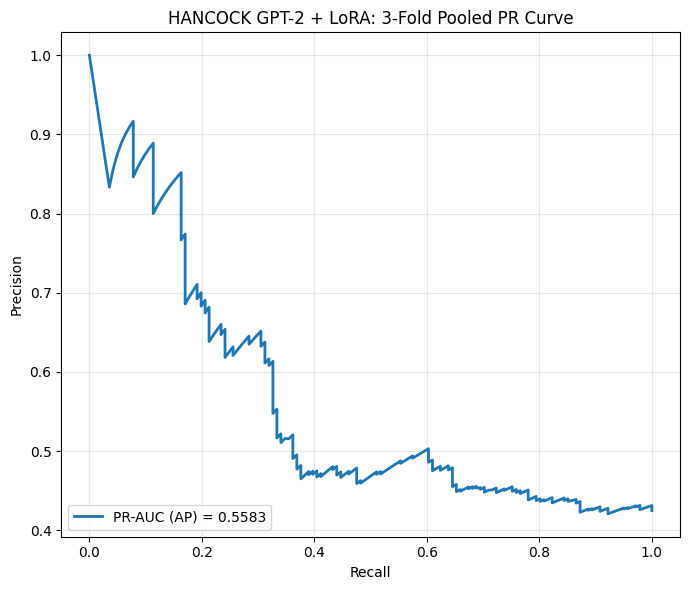


3-FOLD CROSS-VALIDATION COMPLETE
Saved results to: /content/HANCOCK_GPT2_LORA_3_FOLD_CV

Files created:
HANCOCK_GPT2_LoRA_3Fold_PR.png
HANCOCK_GPT2_LoRA_3Fold_ROC.png
cross_validation_settings.csv
fold_1_best_model.pth
fold_1_heldout_predictions.csv
fold_1_training_history.csv
fold_2_best_model.pth
fold_2_heldout_predictions.csv
fold_2_training_history.csv
fold_3_best_model.pth
fold_3_heldout_predictions.csv
fold_3_training_history.csv
pooled_out_of_fold_predictions.csv
pooled_out_of_fold_summary.csv
pooled_pr_coordinates.csv
pooled_roc_coordinates.csv
three_fold_mean_sd_summary.csv
three_fold_results.csv


In [5]:
# ============================================================
# HANCOCK GPT-2 + LoRA: STRATIFIED 3-FOLD CROSS-VALIDATION
# Same CV procedure as previous experiment, using LoRA
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from peft import LoraConfig, get_peft_model, TaskType

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

N_SPLITS = 3
CV_SEED = 42
CV_EPOCHS = 500

CV_DIR = Path("HANCOCK_GPT2_LORA_3_FOLD_CV")
CV_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "openai-community/gpt2"

BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# 2. PREPARE THE COMPLETE DATASET
# ------------------------------------------------------------

cv_df = df.copy().reset_index(drop=True)

features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

TARGET = "HPV_Label"

assert all(c in cv_df.columns for c in features + [TARGET])
assert cv_df[TARGET].nunique() == 2

X = cv_df[features].copy()
y = cv_df[TARGET].astype(int).to_numpy()

print("Total patients:", len(cv_df))
print("Class distribution [negative, positive]:",
      np.bincount(y, minlength=2))

# ------------------------------------------------------------
# 3. TOKENIZER AND PATIENT PROMPT
# ------------------------------------------------------------

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def patient_to_text(row):

    age = display_value(row["age_at_initial_diagnosis"])

    sex_value = str(row["sex"]).strip().lower()

    if sex_value in ["1", "male", "m"]:
        sex = "male"
    elif sex_value in ["0", "female", "f"]:
        sex = "female"
    else:
        sex = display_value(row["sex"])

    smoking_value = str(row["smoking_status"]).strip().lower()

    if smoking_value in ["0", "non-smoker", "nonsmoker", "never"]:
        smoking = "a non-smoker"
    elif smoking_value in ["1", "smoker", "current smoker", "yes"]:
        smoking = "a smoker"
    else:
        smoking = display_value(row["smoking_status"])

    site = display_value(row["primary_tumor_site"])
    metastasis = display_value(row["primarily_metastasis"])
    n_stage = display_value(row["pN_stage"])

    prompt = (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available. "
        f"This patient is {age} years old and is {sex}. "
        f"The patient is {smoking}. "
        f"The primary tumour site is {site}. "
        f"The primarily metastasis status is {metastasis}. "
        f"Pathological nodal stage is {n_stage}. "
        "Based on these six clinical features, "
        "predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\nA:"
    )

    return prompt


# ------------------------------------------------------------
# 4. DATASET CLASS
# ------------------------------------------------------------

class HPVTextDataset(Dataset):

    def __init__(self, texts, labels, max_length):
        self.items = []

        for text, label in zip(texts, labels):

            encoded = tokenizer(
                text,
                max_length=max_length,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            self.items.append((
                encoded["input_ids"].squeeze(0),
                encoded["attention_mask"].squeeze(0),
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):

        input_ids, attention_mask, label = self.items[index]

        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "label": torch.tensor(label, dtype=torch.long)
        }


# ------------------------------------------------------------
# 5. GPT-2 + LoRA MODEL
# Same architecture and LoRA settings as your notebook
# ------------------------------------------------------------

class HPVNetGPT2Text(nn.Module):

    def __init__(self, model_name=MODEL_NAME, num_classes=2,
                 dropout=DROPOUT):

        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(model_name)

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        lora_config = LoraConfig(
            r=6,
            lora_alpha=12,
            target_modules=["c_attn"],
            lora_dropout=0.0,
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION
        )

        self.gpt2 = get_peft_model(self.gpt2, lora_config)

        hidden_size = self.gpt2.config.hidden_size

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        hidden_states = outputs.last_hidden_state

        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]

        return self.classifier(pooled_output)


# ------------------------------------------------------------
# 6. HELPER FUNCTIONS
# ------------------------------------------------------------

def select_threshold(scores, labels):

    thresholds = np.unique(
        np.concatenate(([0.0], scores, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                labels, (scores >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(results, key=lambda x: (x[1], -abs(x[0] - 0.5)))


def get_scores(model, loader):

    model.eval()

    scores = []
    labels_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = torch.softmax(logits, dim=1)[:, 1]

            scores.extend(probabilities.cpu().numpy())
            labels_all.extend(batch["label"].numpy())

    return (
        np.asarray(scores, dtype=float),
        np.asarray(labels_all, dtype=int)
    )


def evaluate_loss(model, loader, class_weights):

    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            losses = nn.functional.cross_entropy(
                logits, labels, reduction="none"
            )

            loss = (losses * class_weights[labels]).mean()

            n = labels.size(0)

            total_loss += loss.item() * n
            total_examples += n

    return total_loss / max(total_examples, 1)


# ------------------------------------------------------------
# 7. STRATIFIED 3-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=CV_SEED
)

fold_results = []
fold_histories = []

oof_scores = np.full(len(cv_df), np.nan)
oof_predictions = np.full(len(cv_df), -1, dtype=int)
oof_labels = y.copy()

for fold, (outer_train_idx, test_idx) in enumerate(
    skf.split(X, y), start=1
):

    print("\n" + "=" * 65)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 65)

    seed_everything(CV_SEED + fold)

    # --------------------------------------------------------
    # 7A. Outer training and held-out test data
    # --------------------------------------------------------

    fold_train_idx, val_idx = train_test_split(
        outer_train_idx,
        test_size=0.15,
        random_state=CV_SEED + fold,
        stratify=y[outer_train_idx]
    )

    train_df = cv_df.iloc[fold_train_idx][features].copy()
    val_df = cv_df.iloc[val_idx][features].copy()
    test_df = cv_df.iloc[test_idx][features].copy()

    y_train = y[fold_train_idx]
    y_val = y[val_idx]
    y_test = y[test_idx]

    print("Training patients:", len(train_df))
    print("Validation patients:", len(val_df))
    print("Held-out test patients:", len(test_df))

    print("Training classes:", np.bincount(y_train, minlength=2))
    print("Validation classes:", np.bincount(y_val, minlength=2))
    print("Test classes:", np.bincount(y_test, minlength=2))

    # --------------------------------------------------------
    # 7B. Impute using training data only
    # --------------------------------------------------------

    fill_values = {}

    for c in features:

        if pd.api.types.is_numeric_dtype(train_df[c]):

            value = train_df[c].median()

            if pd.isna(value):
                value = 0

        else:

            modes = train_df[c].dropna().astype(str).mode()
            value = modes.iloc[0] if not modes.empty else "Unknown"

        fill_values[c] = value

        for split in [train_df, val_df, test_df]:

            split[c] = split[c].fillna(value)

            if split[c].dtype == object:
                split[c] = split[c].astype(str).replace({
                    "": "Unknown",
                    "nan": "Unknown",
                    "None": "Unknown"
                })

    # --------------------------------------------------------
    # 7C. Generate prompts
    # --------------------------------------------------------

    train_texts = [
        patient_to_text(row) for _, row in train_df.iterrows()
    ]

    val_texts = [
        patient_to_text(row) for _, row in val_df.iterrows()
    ]

    test_texts = [
        patient_to_text(row) for _, row in test_df.iterrows()
    ]

    # Determine MAX_LENGTH from training prompts only
    train_prompt_lengths = [
        len(tokenizer.encode(t, add_special_tokens=False))
        for t in train_texts
    ]

    MAX_LENGTH = min(
        1024,
        max(32, int(np.ceil(max(train_prompt_lengths) / 8) * 8))
    )

    print("Fold MAX_LENGTH:", MAX_LENGTH)

    # --------------------------------------------------------
    # 7D. Build datasets and loaders
    # --------------------------------------------------------

    train_dataset = HPVTextDataset(
        train_texts, y_train, MAX_LENGTH
    )

    val_dataset = HPVTextDataset(
        val_texts, y_val, MAX_LENGTH
    )

    test_dataset = HPVTextDataset(
        test_texts, y_test, MAX_LENGTH
    )

    train_generator = torch.Generator().manual_seed(
        CV_SEED + fold
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=train_generator,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # --------------------------------------------------------
    # 7E. Initialise a fresh GPT-2 + LoRA model
    # --------------------------------------------------------

    model = HPVNetGPT2Text().to(device)

    model.gpt2.print_trainable_parameters()

    print(
        "Total trainable parameters:",
        sum(p.numel() for p in model.parameters() if p.requires_grad)
    )

    # Class weights calculated from this fold's training data only
    class_counts = np.bincount(y_train, minlength=2)

    class_weights = torch.tensor(
        len(y_train) / (2 * np.maximum(class_counts, 1)),
        dtype=torch.float32,
        device=device
    )

    print(
        "Class weights [negative, positive]:",
        class_weights.detach().cpu().numpy()
    )

    def fold_loss(logits, labels):

        losses = nn.functional.cross_entropy(
            logits, labels, reduction="none"
        )

        return (losses * class_weights[labels]).mean()

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # --------------------------------------------------------
    # 7F. Train and select best validation BA checkpoint
    # --------------------------------------------------------

    best_val_ba = -float("inf")
    best_epoch = None
    best_threshold = None
    best_state = None

    history = []

    for epoch in range(1, CV_EPOCHS + 1):

        model.train()

        train_loss_sum = 0.0
        train_examples = 0

        for batch in train_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = fold_loss(logits, labels)

            loss.backward()
            optimizer.step()

            n = labels.size(0)

            train_loss_sum += loss.item() * n
            train_examples += n

        train_loss = train_loss_sum / max(train_examples, 1)

        val_loss = evaluate_loss(
            model, val_loader, class_weights
        )

        val_scores, val_labels = get_scores(model, val_loader)

        val_auc = roc_auc_score(val_labels, val_scores)
        val_ap = average_precision_score(val_labels, val_scores)

        val_threshold, val_ba = select_threshold(
            val_scores, val_labels
        )

        history.append({
            "Fold": fold,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Validation_Loss": val_loss,
            "Validation_ROC_AUC": val_auc,
            "Validation_PR_AUC": val_ap,
            "Validation_Balanced_Accuracy": val_ba,
            "Validation_Threshold": val_threshold
        })

        if val_ba > best_val_ba:

            best_val_ba = float(val_ba)
            best_epoch = epoch
            best_threshold = float(val_threshold)

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        if epoch % 50 == 0:

            print(
                f"Fold {fold} | Epoch {epoch}/{CV_EPOCHS} | "
                f"Train Loss={train_loss:.4f} | "
                f"Val Loss={val_loss:.4f} | "
                f"Val ROC-AUC={val_auc:.4f} | "
                f"Val PR-AUC={val_ap:.4f} | "
                f"Val BA={val_ba:.4f} | "
                f"Threshold={val_threshold:.6f}"
            )

    # Save fold training history
    history_df = pd.DataFrame(history)

    history_df.to_csv(
        CV_DIR / f"fold_{fold}_training_history.csv",
        index=False
    )

    fold_histories.append(history_df)

    # --------------------------------------------------------
    # 7G. Load best checkpoint and evaluate held-out fold
    # --------------------------------------------------------

    model.load_state_dict(best_state)

    checkpoint_path = CV_DIR / f"fold_{fold}_best_model.pth"

    torch.save({
        "fold": fold,
        "epoch": best_epoch,
        "threshold": best_threshold,
        "model_state_dict": best_state,
        "features": features,
        "max_length": MAX_LENGTH
    }, checkpoint_path)

    test_scores, test_labels = get_scores(model, test_loader)

    test_predictions = (
        test_scores >= best_threshold
    ).astype(int)

    test_auc = roc_auc_score(test_labels, test_scores)
    test_ap = average_precision_score(test_labels, test_scores)

    test_ba = balanced_accuracy_score(
        test_labels, test_predictions
    )

    test_f1 = f1_score(
        test_labels, test_predictions, zero_division=0
    )

    cm = confusion_matrix(
        test_labels, test_predictions, labels=[0, 1]
    )

    print("\nFOLD", fold, "BEST CHECKPOINT")
    print("Best epoch:", best_epoch)
    print("Best validation BA:", round(best_val_ba, 4))
    print("Validation threshold:", round(best_threshold, 6))

    print("\nHELD-OUT TEST RESULTS")

    print(classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

    print(f"Test ROC-AUC: {test_auc:.4f}")
    print(f"Test PR-AUC (AP): {test_ap:.4f}")
    print(f"Test Balanced Accuracy: {test_ba:.4f}")
    print(f"Test F1-score: {test_f1:.4f}")

    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)

    # Store held-out predictions in their original dataset positions
    oof_scores[test_idx] = test_scores
    oof_predictions[test_idx] = test_predictions

    fold_results.append({
        "Fold": fold,
        "Best_Epoch": best_epoch,
        "Best_Validation_BA": best_val_ba,
        "Validation_Threshold": best_threshold,
        "Test_ROC_AUC": test_auc,
        "Test_PR_AUC": test_ap,
        "Test_Balanced_Accuracy": test_ba,
        "Test_F1": test_f1,
        "TN": int(cm[0, 0]),
        "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]),
        "TP": int(cm[1, 1])
    })

    pd.DataFrame({
        "Original_Index": test_idx,
        "True_Label": test_labels,
        "HPV_Positive_Score": test_scores,
        "Predicted_Label": test_predictions,
        "Threshold": best_threshold
    }).to_csv(
        CV_DIR / f"fold_{fold}_heldout_predictions.csv",
        index=False
    )

    del model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. FOLD RESULTS: MEAN ± STANDARD DEVIATION
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(fold_results)

fold_results_df.to_csv(
    CV_DIR / "three_fold_results.csv",
    index=False
)

metrics = [
    "Test_ROC_AUC",
    "Test_PR_AUC",
    "Test_Balanced_Accuracy",
    "Test_F1"
]

summary_rows = []

for metric in metrics:

    mean_value = fold_results_df[metric].mean()
    std_value = fold_results_df[metric].std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "Standard_Deviation": std_value,
        "Mean ± SD": f"{mean_value:.4f} ± {std_value:.4f}"
    })

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    CV_DIR / "three_fold_mean_sd_summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("3-FOLD CROSS-VALIDATION RESULTS")
print("=" * 65)

print(fold_results_df.to_string(index=False))

print("\nMEAN ± STANDARD DEVIATION")

print(summary_df.to_string(index=False))


# ------------------------------------------------------------
# 9. POOLED OUT-OF-FOLD METRICS
# ------------------------------------------------------------

assert not np.isnan(oof_scores).any()
assert (oof_predictions >= 0).all()

pooled_auc = roc_auc_score(oof_labels, oof_scores)
pooled_ap = average_precision_score(oof_labels, oof_scores)

pooled_ba = balanced_accuracy_score(
    oof_labels, oof_predictions
)

pooled_f1 = f1_score(
    oof_labels, oof_predictions, zero_division=0
)

pooled_cm = confusion_matrix(
    oof_labels, oof_predictions, labels=[0, 1]
)

print("\n" + "=" * 65)
print("POOLED OUT-OF-FOLD RESULTS")
print("=" * 65)

print(f"Pooled ROC-AUC: {pooled_auc:.4f}")
print(f"Pooled PR-AUC (AP): {pooled_ap:.4f}")
print(f"Pooled Balanced Accuracy: {pooled_ba:.4f}")
print(f"Pooled F1-score: {pooled_f1:.4f}")

print("\nPooled confusion matrix [[TN, FP], [FN, TP]]:")
print(pooled_cm)

print("\nPooled classification report:")

print(classification_report(
    oof_labels,
    oof_predictions,
    labels=[0, 1],
    target_names=["HPV Negative", "HPV Positive"],
    digits=4,
    zero_division=0
))

pd.DataFrame({
    "True_Label": oof_labels,
    "HPV_Positive_Score": oof_scores,
    "Predicted_Label": oof_predictions
}).to_csv(
    CV_DIR / "pooled_out_of_fold_predictions.csv",
    index=False
)

pooled_summary = pd.DataFrame([{
    "Dataset": "HANCOCK",
    "Model": "GPT-2 + LoRA",
    "Folds": N_SPLITS,
    "Pooled_ROC_AUC": pooled_auc,
    "Pooled_PR_AUC": pooled_ap,
    "Pooled_Balanced_Accuracy": pooled_ba,
    "Pooled_F1": pooled_f1,
    "TN": int(pooled_cm[0, 0]),
    "FP": int(pooled_cm[0, 1]),
    "FN": int(pooled_cm[1, 0]),
    "TP": int(pooled_cm[1, 1])
}])

pooled_summary.to_csv(
    CV_DIR / "pooled_out_of_fold_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 10. POOLED OUT-OF-FOLD ROC CURVE
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    oof_labels, oof_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr, tpr,
    linewidth=2,
    label=f"ROC-AUC = {pooled_auc:.4f}"
)

plt.plot(
    [0, 1], [0, 1],
    "--",
    linewidth=1.5,
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HANCOCK GPT-2 + LoRA: 3-Fold Pooled ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CV_DIR / "HANCOCK_GPT2_LoRA_3Fold_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
}).to_csv(
    CV_DIR / "pooled_roc_coordinates.csv",
    index=False
)


# ------------------------------------------------------------
# 11. POOLED OUT-OF-FOLD PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision, recall, pr_thresholds = precision_recall_curve(
    oof_labels, oof_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall, precision,
    linewidth=2,
    label=f"PR-AUC (AP) = {pooled_ap:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HANCOCK GPT-2 + LoRA: 3-Fold Pooled PR Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CV_DIR / "HANCOCK_GPT2_LoRA_3Fold_PR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "Precision": precision,
    "Recall": recall
}).to_csv(
    CV_DIR / "pooled_pr_coordinates.csv",
    index=False
)


# ------------------------------------------------------------
# 12. SAVE CROSS-VALIDATION SETTINGS
# ------------------------------------------------------------

settings = {
    "Dataset": "HANCOCK",
    "Model": "GPT-2 + LoRA",
    "Base_Model": MODEL_NAME,
    "Number_of_Folds": N_SPLITS,
    "CV_Seed": CV_SEED,
    "Epochs_Per_Fold": CV_EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Dropout": DROPOUT,
    "LoRA_r": 6,
    "LoRA_alpha": 12,
    "LoRA_target_modules": "c_attn",
    "LoRA_dropout": 0.0,
    "LoRA_bias": "none",
    "Features": ", ".join(features),
    "Number_of_Features": len(features),
    "Target": TARGET,
    "Positive_Class": 1,
    "Inner_Validation_Split": "15% of outer training fold",
    "Preprocessing": "Imputation fitted on fold training data only",
    "Checkpoint_Selection": "Best validation balanced accuracy",
    "Threshold_Selection": "Maximise validation balanced accuracy; ties closest to 0.5",
    "Evaluation": "Held-out fold",
    "Summary": "Mean and standard deviation across three held-out folds",
    "Pooled_Metrics": "Aggregated out-of-fold predictions"
}

pd.DataFrame([settings]).to_csv(
    CV_DIR / "cross_validation_settings.csv",
    index=False
)

print("\n" + "=" * 65)
print("3-FOLD CROSS-VALIDATION COMPLETE")
print("=" * 65)

print("Saved results to:", CV_DIR.resolve())
print("\nFiles created:")
for path in sorted(CV_DIR.iterdir()):
    print(path.name)